# N166 · Budgeted control with factual delayed feedback

One live training learner per trajectory. Use the two N161/N164 streams,
15,232 arrivals per trajectory, and two training seeds. Each new policy starts
from the shared warm RGB64 MAE and fresh AdamW. Quarter-rate references are
reused at the same seeds and streams. Twenty new trajectories are scheduled.

At every 16th arrival choose skip, quarter or nominal for the current image.
Use quarter on the intervening arrivals. The following 16 images reveal the mean
incoming pre-update loss. Their last observation is available before the next
rate decision. Input features reach back at most 128 arrivals.

The matched budget assigns nine nominal, two quarter and one skip decision per
12 opportunities. The final three opportunities use quarter. The four matched
policies are a fixed periodic schedule, quota-proportional random choices,
frozen preview, and adapting preview. Nominal at every decision opportunity is
a larger-dose reference. Quarter and nominal cost approximately the same per
optimizer step. LR exposure and actual training computation are reported separately.

The preview policies use the established 14 inputs plus current training-view
loss, gradient norm, gradient/momentum alignment, and proposed AdamW displacement.
Only decision opportunities compute those features. Accepted steps reuse the
preview gradient. Candidate learner branches and extra branch updates are zero.

Fit the predictor from N164's 261 saved offline paired origins. Calibrate actor
prices and temperature from 117 separate calibration origins. Neither deployment
pool fits the prior. Rate effects are predicted relative to quarter. Subtract
calibration mean effects to express each rate's opportunity cost. Remaining quotas
pace stochastic choices. A 20% mixture with quota-proportional sampling ensures
positive probabilities for available rates.

Frozen preview retains its fitted coefficients. Adapting preview observes only
the actual chosen loss after the window closes. Its effect heads use doubly
robust pseudo outcomes with the issued forecasts and logged probabilities. Update
an effect only while both that rate and quarter had positive probability.
Use probability-dependent regression weights and a persistent offline precision
and coefficient prior. The shared level forecast also adapts from factual
residuals. Pseudo outcomes are estimates; they are not measured paired effects.

Every 128 arrivals select 64 temporally spaced past images. Re-encode identical
IDs before the decision and after the 16-arrival window. Record measured RankMe,
variance and their same-membership changes. Record a common final 64-image panel
and the independent fixed day/night audit. These health measurements initially
monitor the trade-off. The current controller objective is delayed incoming loss.

Plot actual incoming loss, actual trained-image loss, measured RankMe and variance.
Report H16 forecast RMSE against recent-loss persistence and a separate scalar H1
forecast against last-image persistence. Unchosen counterfactual losses are
unobserved online. The existing clip-disjoint archives are development data.

Each clip saves the learner, optimizer, pending factual window, predictor state,
scalar forecaster and rate budget atomically. A watchdog resumes unexpectedly
exited workers and a Windows task supervises the watchdog. The notebook refreshes
every 15 seconds. Keep at least 3 GiB free. The PC driver caches stream images;
its process RAM includes that cache as well as learning and reporting.


## Live status

**complete** · All budgeted single-learner comparisons completed

Updated UTC `2026-11-08T05:18:27+00:00` · PID `29124`.

All policies, both pools, and both seeds are complete.

Free disk **15.3 GiB** with a 3 GiB reserve.

## Actual loss, health and rate budgets

| Seed / pool / arm | Images | Incoming loss | Training loss | Skip / quarter / nominal | LR dose | Mean RankMe64 | Final RankMe64 | Audit loss |
|---|---:|---:|---:|---|---:|---:|---:|---:|
| seed_0/pool_1/quarter_reference | 15,232 | 0.794880 | 0.77578 | 0 / 15232 / 0 | 3808.00 | — | 1.3802 | 1.05340 |
| seed_0/pool_1/periodic | 15,232 | 0.794888 | 0.77738 | 79 / 14442 / 711 | 4321.50 | 1.5909 | 1.2721 | 1.05728 |
| seed_0/pool_1/random | 15,232 | 0.796640 | 0.77890 | 79 / 14442 / 711 | 4321.50 | 1.6408 | 1.4726 | 1.07952 |
| seed_0/pool_1/frozen_preview | 15,232 | 0.796100 | 0.77831 | 79 / 14442 / 711 | 4321.50 | 1.6527 | 1.6552 | 1.09132 |
| seed_0/pool_1/adaptive_preview | 15,232 | 0.796731 | 0.77880 | 79 / 14442 / 711 | 4321.50 | 1.6116 | 1.2812 | 1.12154 |
| seed_0/pool_1/nominal_decisions | 15,232 | 0.792583 | 0.77413 | 0 / 14281 / 951 | 4521.25 | 1.6010 | 1.3271 | 1.11128 |
| seed_0/pool_2/quarter_reference | 15,232 | 0.831038 | 0.81085 | 0 / 15232 / 0 | 3808.00 | — | 1.8955 | 1.02391 |
| seed_0/pool_2/periodic | 15,232 | 0.828996 | 0.80926 | 79 / 14442 / 711 | 4321.50 | 1.6474 | 2.0270 | 0.99166 |
| seed_0/pool_2/random | 15,232 | 0.830209 | 0.81024 | 79 / 14442 / 711 | 4321.50 | 1.6329 | 1.7922 | 1.06393 |
| seed_0/pool_2/frozen_preview | 15,232 | 0.829265 | 0.80963 | 79 / 14442 / 711 | 4321.50 | 1.6061 | 1.6406 | 1.05968 |
| seed_0/pool_2/adaptive_preview | 15,232 | 0.830127 | 0.81017 | 79 / 14442 / 711 | 4321.50 | 1.6287 | 1.6597 | 1.06007 |
| seed_0/pool_2/nominal_decisions | 15,232 | 0.828877 | 0.80919 | 0 / 14281 / 951 | 4521.25 | 1.6063 | 1.6196 | 1.05824 |
| seed_1/pool_1/quarter_reference | 15,232 | 0.793456 | 0.77643 | 0 / 15232 / 0 | 3808.00 | — | 1.5476 | 1.10654 |
| seed_1/pool_1/periodic | 15,232 | 0.792222 | 0.77488 | 79 / 14442 / 711 | 4321.50 | 1.5538 | 1.4524 | 1.10614 |
| seed_1/pool_1/random | 15,232 | 0.792250 | 0.77482 | 79 / 14442 / 711 | 4321.50 | 1.5266 | 1.4908 | 1.11557 |
| seed_1/pool_1/frozen_preview | 15,232 | 0.792106 | 0.77503 | 79 / 14442 / 711 | 4321.50 | 1.6133 | 1.2847 | 1.08133 |
| seed_1/pool_1/adaptive_preview | 15,232 | 0.792771 | 0.77556 | 79 / 14442 / 711 | 4321.50 | 1.5711 | 1.5992 | 0.93006 |
| seed_1/pool_1/nominal_decisions | 15,232 | 0.791349 | 0.77423 | 0 / 14281 / 951 | 4521.25 | 1.6039 | 1.2914 | 1.09575 |
| seed_1/pool_2/quarter_reference | 15,232 | 0.831907 | 0.81185 | 0 / 15232 / 0 | 3808.00 | — | 2.0239 | 0.95509 |
| seed_1/pool_2/periodic | 15,232 | 0.830952 | 0.81124 | 79 / 14442 / 711 | 4321.50 | 1.6099 | 1.7666 | 0.98140 |
| seed_1/pool_2/random | 15,232 | 0.831590 | 0.81179 | 79 / 14442 / 711 | 4321.50 | 1.5804 | 1.7838 | 1.09397 |
| seed_1/pool_2/frozen_preview | 15,232 | 0.831357 | 0.81158 | 79 / 14442 / 711 | 4321.50 | 1.5731 | 1.6615 | 1.06394 |
| seed_1/pool_2/adaptive_preview | 15,232 | 0.831649 | 0.81179 | 79 / 14442 / 711 | 4321.50 | 1.5934 | 1.7471 | 1.01081 |
| seed_1/pool_2/nominal_decisions | 15,232 | 0.831105 | 0.81113 | 0 / 14281 / 951 | 4521.25 | 1.5820 | 1.7000 | 1.07622 |

## Factual forecast errors and online updates

RMSE shows forecast / persistence on the same observed outcomes.

| Arm | Closed windows | H16 loss RMSE | H1 loss RMSE | Effect-head updates skip / nominal | Effect drift |
|---|---:|---:|---:|---:|---|
| seed_0/pool_1/periodic | 951 | — | 0.03637 / 0.03664 | 0 / 0 | 0 / 0 |
| seed_0/pool_1/random | 951 | — | 0.03620 / 0.03646 | 0 / 0 | 0 / 0 |
| seed_0/pool_1/frozen_preview | 951 | 0.06437 / 0.08022 | 0.03642 / 0.03668 | 0 / 0 | 0 / 0 |
| seed_0/pool_1/adaptive_preview | 951 | 0.04542 / 0.08067 | 0.03677 / 0.03704 | 284 / 483 | 0.006027 / 0.005001 |
| seed_0/pool_1/nominal_decisions | 951 | — | 0.03639 / 0.03666 | 0 / 0 | 0 / 0 |
| seed_0/pool_2/periodic | 951 | — | 0.03484 / 0.03511 | 0 / 0 | 0 / 0 |
| seed_0/pool_2/random | 951 | — | 0.03510 / 0.03537 | 0 / 0 | 0 / 0 |
| seed_0/pool_2/frozen_preview | 951 | 0.06767 / 0.08013 | 0.03480 / 0.03507 | 0 / 0 | 0 / 0 |
| seed_0/pool_2/adaptive_preview | 951 | 0.05084 / 0.08095 | 0.03507 / 0.03534 | 380 / 577 | 0.003151 / 0.005148 |
| seed_0/pool_2/nominal_decisions | 951 | — | 0.03484 / 0.03511 | 0 / 0 | 0 / 0 |
| seed_1/pool_1/periodic | 951 | — | 0.03560 / 0.03584 | 0 / 0 | 0 / 0 |
| seed_1/pool_1/random | 951 | — | 0.03595 / 0.03620 | 0 / 0 | 0 / 0 |
| seed_1/pool_1/frozen_preview | 951 | 0.06283 / 0.07482 | 0.03528 / 0.03551 | 0 / 0 | 0 / 0 |
| seed_1/pool_1/adaptive_preview | 951 | 0.04398 / 0.07544 | 0.03560 / 0.03585 | 362 / 499 | 0.003523 / 0.005684 |
| seed_1/pool_1/nominal_decisions | 951 | — | 0.03544 / 0.03568 | 0 / 0 | 0 / 0 |
| seed_1/pool_2/periodic | 951 | — | 0.03511 / 0.03539 | 0 / 0 | 0 / 0 |
| seed_1/pool_2/random | 951 | — | 0.03489 / 0.03516 | 0 / 0 | 0 / 0 |
| seed_1/pool_2/frozen_preview | 951 | 0.06885 / 0.08153 | 0.03491 / 0.03518 | 0 / 0 | 0 / 0 |
| seed_1/pool_2/adaptive_preview | 951 | 0.05123 / 0.08143 | 0.03487 / 0.03514 | 452 / 607 | 0.002667 / 0.006243 |
| seed_1/pool_2/nominal_decisions | 951 | — | 0.03493 / 0.03520 | 0 / 0 | 0 / 0 |

## Computation

| Arm | Wall minutes | Update seconds | Preview seconds | Observation seconds | Preview backward passes | Candidate copies / extra optimizer steps |
|---|---:|---:|---:|---:|---:|---:|
| seed_0/pool_1/periodic | 22.1 | 972.5 | 0.0 | 344.9 | 0 | 0 / 0 |
| seed_0/pool_1/random | 14.8 | 644.9 | 0.0 | 236.2 | 0 | 0 / 0 |
| seed_0/pool_1/frozen_preview | 15.4 | 602.1 | 51.5 | 261.0 | 951 | 0 / 0 |
| seed_0/pool_1/adaptive_preview | 15.2 | 588.5 | 54.9 | 259.1 | 951 | 0 / 0 |
| seed_0/pool_1/nominal_decisions | 14.0 | 611.1 | 0.0 | 223.4 | 0 | 0 / 0 |
| seed_0/pool_2/periodic | 14.6 | 636.3 | 0.0 | 233.6 | 0 | 0 / 0 |
| seed_0/pool_2/random | 14.1 | 616.1 | 0.0 | 225.6 | 0 | 0 / 0 |
| seed_0/pool_2/frozen_preview | 15.1 | 589.8 | 52.0 | 257.4 | 951 | 0 / 0 |
| seed_0/pool_2/adaptive_preview | 14.9 | 580.1 | 53.3 | 253.8 | 951 | 0 / 0 |
| seed_0/pool_2/nominal_decisions | 14.9 | 650.8 | 0.0 | 235.7 | 0 | 0 / 0 |
| seed_1/pool_1/periodic | 14.1 | 615.2 | 0.0 | 223.9 | 0 | 0 / 0 |
| seed_1/pool_1/random | 14.5 | 630.4 | 0.0 | 230.5 | 0 | 0 / 0 |
| seed_1/pool_1/frozen_preview | 15.5 | 605.5 | 52.9 | 261.5 | 951 | 0 / 0 |
| seed_1/pool_1/adaptive_preview | 15.7 | 616.9 | 52.4 | 262.8 | 951 | 0 / 0 |
| seed_1/pool_1/nominal_decisions | 13.9 | 606.7 | 0.0 | 221.6 | 0 | 0 / 0 |
| seed_1/pool_2/periodic | 14.3 | 623.5 | 0.0 | 226.7 | 0 | 0 / 0 |
| seed_1/pool_2/random | 14.1 | 613.9 | 0.0 | 222.7 | 0 | 0 / 0 |
| seed_1/pool_2/frozen_preview | 18.0 | 700.0 | 64.6 | 306.8 | 951 | 0 / 0 |
| seed_1/pool_2/adaptive_preview | 15.5 | 603.1 | 50.5 | 269.9 | 951 | 0 / 0 |
| seed_1/pool_2/nominal_decisions | 14.7 | 637.9 | 0.0 | 235.6 | 0 | 0 / 0 |

## Completed comparisons

Positive loss gains favor the predictor policy.

| Seed / pool / policy | Gain vs periodic | Gain vs random | Gain vs quarter | RankMe64 difference vs random |
|---|---:|---:|---:|---:|
| seed_0/pool_1/frozen_preview | -0.001212 | +0.000540 | -0.001220 | +0.01186 |
| seed_0/pool_1/adaptive_preview | -0.001843 | -0.000091 | -0.001851 | -0.02917 |
| seed_0/pool_2/frozen_preview | -0.000269 | +0.000943 | +0.001773 | -0.02681 |
| seed_0/pool_2/adaptive_preview | -0.001130 | +0.000082 | +0.000911 | -0.00414 |
| seed_1/pool_1/frozen_preview | +0.000116 | +0.000144 | +0.001351 | +0.08672 |
| seed_1/pool_1/adaptive_preview | -0.000549 | -0.000521 | +0.000685 | +0.04451 |
| seed_1/pool_2/frozen_preview | -0.000406 | +0.000232 | +0.000550 | -0.00735 |
| seed_1/pool_2/adaptive_preview | -0.000698 | -0.000060 | +0.000258 | +0.01299 |

### Actual loss, RankMe and variance

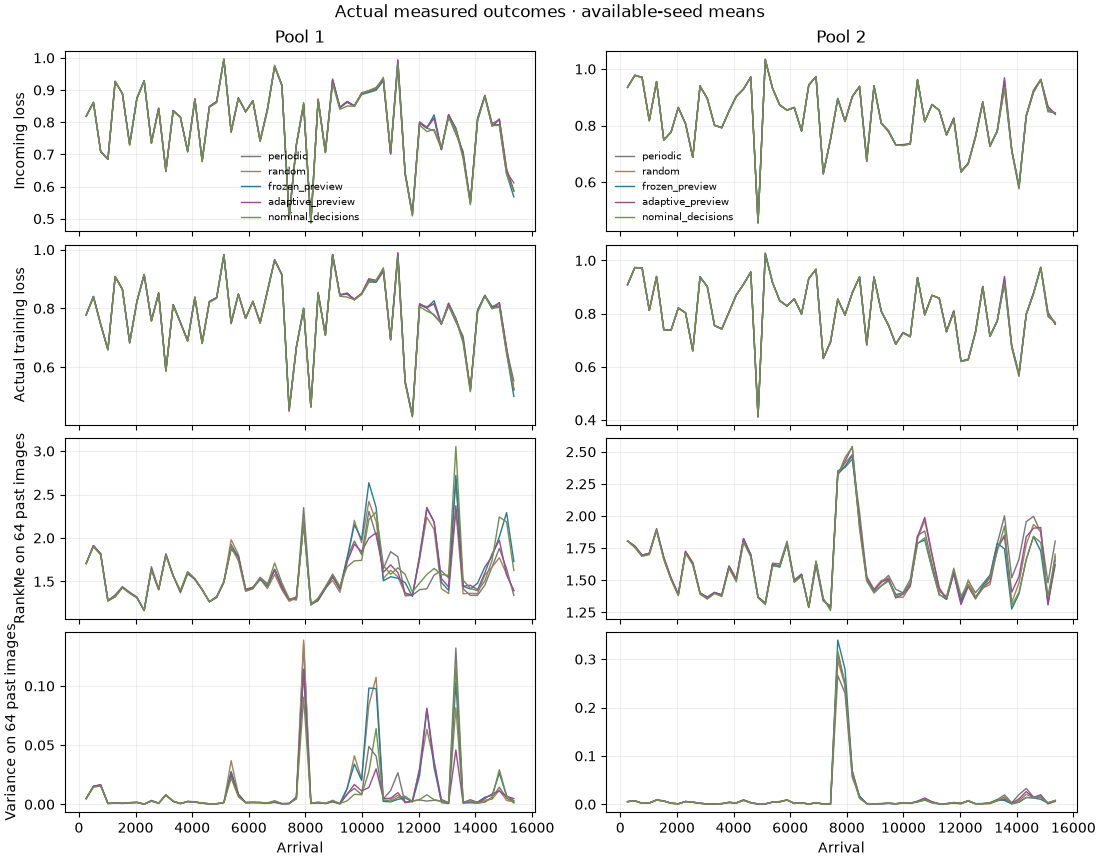

### Forecast RMSE versus persistence

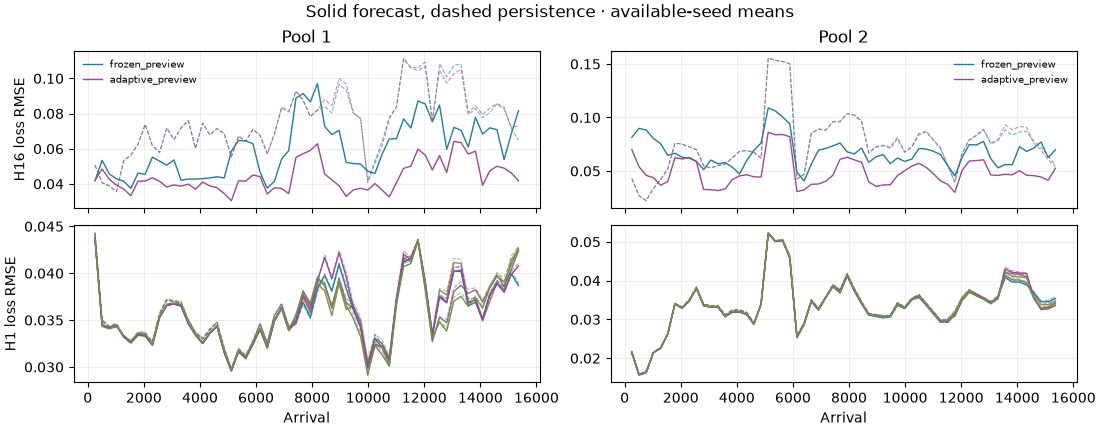